# Self-supervised và CLIP

Gán nhãn ảnh tốn công, nhưng ảnh chưa có nhãn vẫn dùng để học được. Self-supervised learning tự tạo bài tập từ dữ liệu: hai bản cắt, xoay khác nhau của cùng một ảnh phải cho vector gần nhau. CLIP học từ ảnh kèm chú thích trên Internet: ảnh và chú thích của nó phải cho vector gần nhau. Kết quả là ảnh và câu chữ nằm trong cùng một không gian vector, nên có thể tìm ảnh bằng một câu mô tả bất kỳ mà không cần huấn luyện lại.

> **Mục tiêu**
>
> - Hiểu self-supervised learning học từ đâu khi không có nhãn.
> - Tính contrastive loss (InfoNCE); hiểu temperature.
> - Huấn luyện encoder không dùng nhãn rồi đánh giá bằng linear probe.
> - Tìm ảnh bằng câu chữ với CLIP; đo bằng recall@k.

## Không có nhãn lớp vẫn có một nhiệm vụ để học

Self-supervised learning tạo mục tiêu từ cấu trúc của chính dữ liệu. Ta có thể che một phần input rồi bắt model đoán lại phần bị che (BERT ở Chương 6 học theo cách này), xoay ảnh một góc rồi bắt model đoán góc, hoặc làm hai phiên bản của cùng một ảnh rồi bắt biểu diễn của chúng gần nhau. Nhiệm vụ như vậy gọi là pretext task: bản thân nó không phải mục tiêu cuối, nhưng muốn làm tốt thì model phải học được đặc trưng dùng được cho việc khác. “Không có nhãn” chỉ có nghĩa là không có nhãn do người gán cho từng mẫu; ta vẫn thiết kế mục tiêu, giả định và cách đánh giá.

**Hỏi nhanh.** Một đội muốn tận dụng 800 ảnh không nhãn bằng pretext task “đoán xem ảnh đã bị xoay 0°, 90°, 180° hay 270°”. Bộ ảnh là các hình học vốn được vẽ ở góc xoay ngẫu nhiên. Pretext task này có hợp không?

- A. Hợp, vì nhãn góc xoay được tạo miễn phí từ dữ liệu
- B. Không hợp, vì ảnh gốc không có hướng chuẩn để so
- C. Hợp, nếu train đủ lâu để đoán đúng mọi góc
- D. Không hợp, vì pretext task nào cũng cần nhãn người

<details><summary>Đáp án</summary>

B. Không hợp, vì ảnh gốc không có hướng chuẩn để so

Pretext xoay dựa vào giả định ảnh gốc có một hướng “đứng” chuẩn, như ảnh chụp người hay nhà cửa. Ở đây hình vốn đã xoay ngẫu nhiên, nên một ảnh xoay 90° trông giống hệt một ảnh gốc khác. Góc gần như không đoán được từ nội dung, và model không có gì để học. Nhãn miễn phí chưa chắc là nhãn có nghĩa. Train lâu hơn cũng không tạo ra thông tin vốn không có. Còn pretext task thì không cần nhãn người, đó chính là ý của self-supervised.

</details>

Contrastive learning (học tương phản) chọn cách thứ ba. Ta tạo cặp positive (cặp phù hợp) và coi các cặp còn lại trong batch là negative. [SimCLR](https://arxiv.org/abs/2002.05709) lấy một ảnh, áp hai phép augmentation ngẫu nhiên (cắt, xoay, đổi màu…) để có hai view, rồi yêu cầu encoder nhận ra hai view ấy thuộc cùng một ảnh giữa nhiều ảnh khác. Giả định ngầm là augmentation giữ lại nội dung quan trọng. Một crop chỉ có nền trống và một crop chứa mặt người chưa chắc có chung nội dung; ép chúng gần nhau là dạy model một điều sai.



Negative không chỉ để trang trí. Nếu chỉ kéo hai view lại gần nhau, encoder có một lời giải lười: trả về cùng một vector cho mọi ảnh. Khi đó mọi cặp đều gần tuyệt đối, loss đạt cực tiểu, còn biểu diễn không phân biệt được gì. Hiện tượng này gọi là sụp đổ (collapse). Negative buộc các ảnh khác nhau phải tách ra; các phương pháp bỏ negative như BYOL hay SimSiam phải dùng mẹo kiến trúc khác để tránh collapse.

**Hỏi nhanh.** Một đội bỏ negative, chỉ minimize $-\cos(\mathbf z_1, \mathbf z_2)$ giữa hai view của cùng một ảnh. Sau vài epoch, loss bằng đúng $-1$ trên mọi batch. Chuyện gì đang xảy ra?

- A. Encoder đã học xong, có thể dừng và dùng ngay
- B. Learning rate quá lớn làm loss kẹt ở cực trị
- C. Hai view quá giống nhau, cần augmentation mạnh hơn
- D. Nhiều khả năng encoder trả về một vector cho mọi ảnh

<details><summary>Đáp án</summary>

D. Nhiều khả năng encoder trả về một vector cho mọi ảnh

Nếu mọi ảnh cho cùng một vector thì cặp nào cũng có cosine 1, và loss đạt cực tiểu mà không cần nhìn ảnh. Cần kiểm độ đa dạng của embedding, ví dụ độ lệch chuẩn từng chiều trên một batch, hoặc cosine giữa các ảnh khác nhau. Augmentation mạnh hơn không chặn được lời giải này, vì vector hằng thắng với mọi view. Learning rate lớn thường làm loss dao động, chứ không dừng đúng ở cận dưới. Loss chạm cận dưới trên mọi batch là dấu hiệu đáng ngờ, không phải thành công.

</details>

[CLIP](https://arxiv.org/abs/2103.00020) áp cùng cơ chế cho cặp ảnh–văn bản: một encoder cho ảnh, một encoder cho chữ, học để mỗi ảnh gần caption đi kèm nó hơn các caption khác trong batch. Caption do người viết, nên CLIP học từ một dạng giám sát yếu bằng ngôn ngữ tự nhiên chứ không phải “không có thông tin nhãn”. Điểm chung với SimCLR là cách học: ghép cặp trong batch và so với mọi cặp còn lại.

## Vector gần nhau theo tiêu chuẩn nào?

Encoder ảnh $f(x)$ và encoder chữ $g(t)$ tạo vector cùng chiều $D$. Ta chuẩn hóa mỗi vector về độ dài 1 để dot product trở thành cosine similarity:

$$\mathbf{u}=\frac{f(x)}{\lVert f(x)\rVert},\quad
\mathbf{v}=\frac{g(t)}{\lVert g(t)\rVert},\quad
s(x,t)=\mathbf{u}^{\top}\mathbf{v}.$$

Cosine đo hướng, không đo độ dài. Vector 0 không có hướng; code cần xử lý hoặc báo lỗi thay vì chia cho 0. Cùng số chiều chưa đủ để so: như bài 4.5 đã nhấn mạnh, hai encoder phải được học chung thì các trục mới có nghĩa tương thích.

### Ví dụ tính tay

Ảnh có vector $(1,0)$, mô tả có vector $(0.9,0.1)$. Độ dài mô tả là $\sqrt{0.82}$, cosine $0.9/\sqrt{0.82}\approx0.9939$. Mô tả $(0,1)$ có cosine 0. Ta dựng ba cặp vector hai chiều, ảnh $i$ đi với mô tả $i$, để tập trung vào cách ghép và xếp hạng.

In [ ]:
import numpy as np

def normalize_rows(vectors):
    lengths = np.linalg.norm(vectors, axis=1, keepdims=True)
    assert np.all(lengths > 0)
    return vectors / lengths

image_vectors = normalize_rows(np.array([[1., 0.],
                                        [0., 1.],
                                        [-1., 0.]]))
text_vectors = normalize_rows(np.array([[0.9, 0.1],
                                       [0.1, 0.9],
                                       [-0.9, 0.1]]))
similarities = image_vectors @ text_vectors.T
print(similarities.round(4))
print("best text for each image:", similarities.argmax(axis=1).tolist())
print("best image for text 1:", int(similarities[:, 1].argmax()))

[[ 0.9939  0.1104 -0.9939]
 [ 0.1104  0.9939  0.1104]
 [-0.9939 -0.1104  0.9939]]
best text for each image: [0, 1, 2]
best image for text 1: 1


Đọc theo hàng để tìm chữ cho ảnh, theo cột để tìm ảnh cho chữ. Ba cặp vector được đặt sao cho cặp $i$–$i$ gần nhau nhất, nên kết quả đúng cả ba cặp xác nhận code xếp hạng làm đúng phép hình học. Với embedding thật, chất lượng được đo bằng recall@k hoặc metric của đề trên các query chưa dùng để chọn cấu hình.

**Hỏi nhanh.** Ma trận cosine giữa hai ảnh, xếp theo hàng, và ba câu, xếp theo cột, là $\begin{pmatrix}0.9&0.6&0.2\\0.8&0.7&0.1\end{pmatrix}$. Tìm ảnh cho câu thứ hai, tức cột giữa, thì được ảnh nào? Tìm câu cho ảnh thứ hai, tức hàng dưới, thì được câu nào?

- A. Ảnh thứ hai, và ảnh ấy chọn câu thứ hai
- B. Ảnh thứ hai, và ảnh ấy chọn câu thứ nhất
- C. Ảnh thứ nhất, và ảnh thứ hai chọn câu thứ nhất
- D. Ảnh thứ nhất, và ảnh thứ hai chọn câu thứ hai

<details><summary>Đáp án</summary>

B. Ảnh thứ hai, và ảnh ấy chọn câu thứ nhất

Cột giữa có $0.7 > 0.6$, nên câu thứ hai tìm được ảnh thứ hai. Hàng dưới có $0.8 > 0.7$, nên ảnh thứ hai lại gần câu thứ nhất hơn. Argmax theo cột và argmax theo hàng là hai câu hỏi khác nhau, không phải nghịch đảo của nhau. Vì vậy contrastive loss thường tính cả hai chiều. Chọn “ảnh thứ nhất” là nhìn số lớn nhất của cả ma trận, 0.9, thay vì của cột giữa.

</details>

## Contrastive loss làm cặp đúng thắng cặp khác

Trong một batch $N$ cặp ảnh–caption, ma trận điểm $S$ có shape $(N,N)$; hàng $i$ là ảnh $i$, cột $j$ là caption $j$. Cặp đúng nằm trên đường chéo, nên ta muốn ô $(i,i)$ thắng các ô khác trong hàng. Với temperature $\tau>0$:

$$L_{\mathrm{ảnh}}=-\frac1N\sum_i
\log\frac{\exp(S_{i,i}/\tau)}
{\sum_j\exp(S_{i,j}/\tau)}.$$

Đây là cross-entropy của nhiệm vụ “caption nào ghép với ảnh này?”, với target của hàng $i$ là cột $i$. Loss ngược chiều chữ → ảnh dùng transpose của $S$; CLIP lấy trung bình hai chiều.

SimCLR dùng cùng ý trên một ma trận lớn hơn. Batch $N$ ảnh cho $2N$ view; mỗi view $a$ có đúng một partner $p(a)$, là view kia của cùng ảnh. Mọi view còn lại là negative, và chính $a$ bị bỏ khỏi mẫu số:

$$\ell_a=-\log\frac{\exp(s_{a,p(a)}/\tau)}{\sum_{b\ne a}\exp(s_{a,b}/\tau)}.$$

Loss của batch là trung bình $\ell_a$ trên $2N$ view. Tên thường gặp của loss này là InfoNCE hoặc NT-Xent. Trong code, việc bỏ $b=a$ làm bằng cách gán $-\infty$ cho đường chéo trước softmax; nếu không, mỗi view luôn tự giống chính nó với cosine 1. Cùng lý do, muốn mỗi mục tìm mục *khác* gần nhất trong một ma trận cosine, phải chặn đường chéo trước khi lấy argmax. Với $N = 256$ ảnh, mỗi view có 1 positive và $2N - 2 = 510$ negative. Lúc mọi điểm bằng nhau, softmax chia đều cho các ứng viên nên loss bằng $\ln$ của số ứng viên, như $\ln N$ với $N$ cặp kiểu CLIP: một mốc kiểm loss ban đầu như ở bài 3.3.

**Hỏi nhanh.** SimCLR với batch $N = 128$ ảnh, mỗi ảnh có hai view. Mỗi view có bao nhiêu negative? Mẫu số của nó, sau khi bỏ chính nó, có bao nhiêu số hạng?

- A. 127 negative, 128 số hạng
- B. 255 negative, 256 số hạng
- C. 254 negative, 255 số hạng
- D. 254 negative, 256 số hạng

<details><summary>Đáp án</summary>

C. 254 negative, 255 số hạng

Có $2N = 256$ view. Trừ chính nó và partner thì còn 254 negative. Mẫu số gồm partner và 254 negative, tức $2N - 1 = 255$ số hạng. 127 là đếm như CLIP, mỗi ảnh một vector. 256 số hạng là quên bỏ chính nó khỏi mẫu số. 255 negative là quên rằng partner không phải negative.

</details>

Ta xem gradient trên một ma trận logits $3\times3$ cho sẵn, kiểu CLIP, để biết loss đẩy từng ô theo hướng nào. Gradient âm ở ô đúng nghĩa gradient descent tăng điểm đúng; gradient dương ở ô khác nghĩa giảm điểm ấy.

In [ ]:
import torch
import torch.nn.functional as F

torch.set_num_threads(1)
logits = torch.tensor([[2., 0.2, -1.],
                       [0.1, 2., 0.3],
                       [-1., 0.2, 2.]], requires_grad=True)
targets = torch.arange(3)
loss_image = F.cross_entropy(logits, targets)
loss_text = F.cross_entropy(logits.T, targets)
contrastive_loss = (loss_image + loss_text) / 2
contrastive_loss.backward()
print("symmetric loss:", round(contrastive_loss.item(), 4))
print("diagonal gradients:", [round(float(v), 4) for v in logits.grad.diag()])
print("negative gradient [0,1]:", round(logits.grad[0, 1].item(), 4))

symmetric loss: 0.2255
diagonal gradients: [-0.0572, -0.083, -0.0609]
negative gradient [0,1]: 0.0434


Ba ô đường chéo đều có gradient âm, ô `[0,1]` có gradient dương: một bước cập nhật tăng điểm cặp đúng và giảm điểm cặp sai, theo cả hàng lẫn cột.



**Hỏi nhanh.** Trong output trên, cặp thứ hai có gradient ở đường chéo bằng $-0.083$, lớn nhất về độ lớn, dù ba logit đúng đều bằng 2. Vì sao?

- A. Hàng và cột của nó có logit sai cao nhất
- B. Logit đúng của nó lớn nhất trong cả ba cặp
- C. Ô giữa nhận gradient từ cả hàng lẫn cột
- D. Gradient được khởi tạo ngẫu nhiên nên khác nhau

<details><summary>Đáp án</summary>

A. Hàng và cột của nó có logit sai cao nhất

Gradient ở ô đúng là $\frac{(p_{\text{hàng}} - 1) + (p_{\text{cột}} - 1)}{2N}$, với $p$ là xác suất softmax của ô ấy trong hàng và trong cột. Hàng 1 và cột 1, đếm từ 0, tức cặp thứ hai, có logit sai 0.1, 0.3 và 0.2, 0.2. Các số này đều cao hơn ở hàng, cột khác, nên $p \approx 0.75$ là nhỏ nhất, và cặp này bị kéo mạnh nhất: $(-0.249 - 0.249)/6 \approx -0.083$. Ba logit đúng bằng nhau. Mọi ô đường chéo đều nhận gradient từ cả hàng lẫn cột, không riêng ô giữa. Gradient được tính tất định từ logits, không có gì ngẫu nhiên.

</details>

Ô `[0,1]` là negative theo giả định ghép cặp. Nếu caption 1 cũng mô tả đúng ảnh 0, loss vẫn đẩy chúng ra xa: đó là false negative. Với SimCLR, hai ảnh khác nhau của cùng một lớp, chẳng hạn hai tam giác, luôn là negative của nhau, vì thuật toán không biết lớp. Tăng batch thêm negative, nhưng cũng thêm những cặp như vậy.

## Temperature và số negative

Hai lựa chọn quyết định loss contrastive trông thế nào: temperature $\tau$ và số ứng viên trong mẫu số. Đạo hàm của $\ell_a$ theo similarity của một negative $b$ là $p_{a,b}/\tau$, với $p_{a,b}$ là xác suất softmax của ô ấy. Negative càng giống anchor thì $p$ càng lớn và bị đẩy càng mạnh; $\tau$ quyết định sự ưu tiên này lệch đến đâu. Ta xét một hàng có positive cosine 0.8, một negative khó 0.7 và sáu negative dễ 0.

In [ ]:
row_scores = torch.tensor([0.8, 0.7, 0., 0., 0., 0., 0., 0.])  # cột 0 là positive
for tau in [1.0, 0.5, 0.1]:
    probabilities = (row_scores / tau).softmax(0)
    push = probabilities[1:] / tau          # lực đẩy lên từng negative
    hard_share = push[0] / push.sum()
    print(f"tau={tau}: loss {-probabilities[0].log().item():.3f}, "
          f"hard-negative share {hard_share.item():.3f}")

tau=1.0: loss 1.526, hard-negative share 0.251
tau=0.5: loss 1.109, hard-negative share 0.403
tau=0.1: loss 0.315, hard-negative share 0.995


Với $\tau=1$, negative khó nhận khoảng một phần tư tổng lực đẩy, phần còn lại rải cho sáu negative dễ. Với $\tau=0.1$, gần như toàn bộ lực dồn vào negative khó. Đó là điều ta muốn nếu negative khó thật sự khác nghĩa, và là điều có hại nếu nó là false negative, ví dụ một tam giác khác trong batch. $\tau$ quá nhỏ còn làm softmax bão hòa. Vì vậy $\tau$ là một hyperparameter cần dò; CLIP học nó như một tham số thay vì cố định.



**Hỏi nhanh.** SimCLR trên bộ ảnh ba lớp hình, batch 256 ảnh, nên khoảng một phần ba batch cùng lớp với mỗi anchor. Hạ $\tau$ từ 0.5 xuống 0.05 thì rủi ro lớn nhất là gì?

- A. Loss không còn khả vi vì softmax quá nhọn
- B. Số negative trong mẫu số giảm theo $\tau$
- C. Augmentation bị bỏ qua khi tính loss
- D. Lực đẩy dồn vào những ảnh cùng lớp với anchor

<details><summary>Đáp án</summary>

D. Lực đẩy dồn vào những ảnh cùng lớp với anchor

$\tau$ nhỏ dồn gradient vào những negative có similarity cao nhất. Khi một phần ba batch cùng hình với anchor, các negative giống nhất thường chính là ảnh cùng lớp. Loss vì vậy đẩy chúng ra xa, ngược với điều linear probe cần đọc ra. Softmax vẫn khả vi với mọi $\tau > 0$, chỉ bão hòa. Số negative do batch quyết định, không do $\tau$. Augmentation xảy ra trước encoder, không liên quan đến $\tau$.

</details>

Số ứng viên đặt mốc cho loss. Khi encoder chưa phân biệt được gì, mọi similarity như nhau, softmax chia đều cho $K$ ứng viên và loss bằng $-\log(1/K)=\log K$. Với SimCLR, $K=2N-1$. Vì vậy loss của hai lần chạy khác batch không so trực tiếp được: loss 3.0 là tiến bộ lớn khi $K=511$ (mốc $\log511\approx6.24$) nhưng gần đoán mò khi $K=31$ (mốc $\log31\approx3.43$). Batch lớn cho nhiều negative hơn, nhiệm vụ khó hơn và thường cho biểu diễn tốt hơn, nhưng ma trận similarity $2N\times2N$ tăng theo bình phương batch.

**Hỏi nhanh.** Đội A train contrastive kiểu CLIP với batch 1024, loss cuối là 2.9. Đội B dùng batch 64, loss cuối là 2.1. Ta kết luận được gì?

- A. B tốt hơn, vì cùng loại loss mà B thấp hơn
- B. A tốt hơn, vì batch lớn luôn cho biểu diễn tốt hơn
- C. Chưa so được, vì mốc đoán mò là $\log 1024$ và $\log 64$
- D. Chưa so được, vì phải train cả hai cùng số epoch

<details><summary>Đáp án</summary>

C. Chưa so được, vì mốc đoán mò là $\log 1024$ và $\log 64$

Mốc đoán mò của A là $\log 1024 \approx 6.93$, của B là $\log 64 \approx 4.16$, nên hai loss đo hai nhiệm vụ khó khác nhau. Ngay cả độ giảm so với mốc cũng chưa phải metric của nhiệm vụ đích. Muốn so hai encoder thì dùng cùng một phép đo downstream, như linear probe hay recall@k, trên cùng validation. Batch lớn thường giúp, nhưng không phải “luôn”. Cùng số epoch cũng không làm hai loss về cùng thang.

</details>



## Thí nghiệm: học phân biệt hình không cần nhãn

Ta dựng lại ở cỡ nhỏ tình huống của một đề thi thật. Đề USA-NA-AIO 2026 (Vòng 2, Ngày 2, Problem 4) cho ảnh chứa đúng một hình tròn, tam giác hoặc chữ nhật, với vị trí, kích thước, góc xoay và màu ngẫu nhiên; 1000 ảnh train nhưng chỉ 200 ảnh có nhãn, cấm model pretrained, chấm macro-F1. Ở đây ảnh xám $32\times32$ được sinh bằng code, cùng tỉ lệ 200 ảnh có nhãn trên 1000; độ sáng của hình thay cho màu.

In [ ]:
import copy
import math
import torch.nn as nn

SIZE = 32
grid_y, grid_x = np.mgrid[0:SIZE, 0:SIZE] + 0.5   # tâm các pixel

def draw_shape(label, rng):
    cx, cy = rng.uniform(10, 22, size=2)
    radius = rng.uniform(5, 9)
    angle = rng.uniform(0, 2 * np.pi)
    if label == 0:                                   # hình tròn
        mask = (grid_x - cx) ** 2 + (grid_y - cy) ** 2 <= radius ** 2
    else:
        if label == 1:                               # tam giác không đều
            angles = angle + np.array([0, 2, 4]) * np.pi / 3 + rng.uniform(-0.5, 0.5, 3)
            corners = np.stack([np.cos(angles), np.sin(angles)], axis=1) * radius
        else:                                        # chữ nhật xoay
            half_w, half_h = radius * rng.uniform(0.6, 1.0, size=2)
            corners = np.array([[-half_w, -half_h], [half_w, -half_h],
                                [half_w, half_h], [-half_w, half_h]])
            rotation = np.array([[np.cos(angle), -np.sin(angle)],
                                 [np.sin(angle), np.cos(angle)]])
            corners = corners @ rotation.T
        corners = corners + [cx, cy]
        mask = np.ones((SIZE, SIZE), dtype=bool)     # đa giác lồi: cùng phía mọi cạnh
        for (x0, y0), (x1, y1) in zip(corners, np.roll(corners, -1, axis=0)):
            mask &= (x1 - x0) * (grid_y - y0) - (y1 - y0) * (grid_x - x0) >= 0
    image = np.zeros((SIZE, SIZE), dtype=np.float32)
    image[mask] = rng.uniform(0.4, 1.0)              # độ sáng ngẫu nhiên
    return image

def make_shapes(n, rng):
    labels = rng.integers(0, 3, size=n)
    images = np.stack([draw_shape(label, rng) for label in labels])
    return torch.tensor(images).unsqueeze(1), labels

rng = np.random.default_rng(0)
train_images, train_labels = make_shapes(1000, rng)
test_images, test_labels = make_shapes(300, rng)
labeled = slice(0, 200)                              # chỉ 200 ảnh đầu được dùng nhãn
print("train:", tuple(train_images.shape), "test:", tuple(test_images.shape))
print("labels in the 200 labeled images:", np.bincount(train_labels[labeled]).tolist())

train: (1000, 1, 32, 32) test: (300, 1, 32, 32)
labels in the 200 labeled images: [55, 66, 79]


Ba lớp không đều trong 200 ảnh có nhãn (55, 66, 79), nên ta đo bằng macro-F1 như đề. Augmentation chỉ dùng những biến đổi giữ nguyên lớp: xoay một góc bất kỳ, phóng to hoặc thu nhỏ 0.8–1.2 lần, dịch tối đa 10% cạnh ảnh và đổi độ sáng. Hình tròn bị xoay vẫn là hình tròn; đó cũng chính là các biến thiên mà đề mô tả. Encoder là CNN ba tầng có BatchNorm, kết thúc bằng global average pooling cho vector 64 chiều; projection head đưa vector ấy về 32 chiều để tính loss, như SimCLR.



In [ ]:
def augment(images, generator):
    batch = images.shape[0]
    angle = torch.rand(batch, generator=generator) * 2 * math.pi
    scale = 0.8 + 0.4 * torch.rand(batch, generator=generator)
    shift = (torch.rand(batch, 2, generator=generator) - 0.5) * 0.4
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([torch.stack([cos, -sin, shift[:, 0]], dim=1),
                         torch.stack([sin, cos, shift[:, 1]], dim=1)], dim=1)
    grid = F.affine_grid(theta, list(images.shape), align_corners=False)
    views = F.grid_sample(images, grid, align_corners=False)
    brightness = 0.6 + 0.8 * torch.rand(batch, 1, 1, 1, generator=generator)
    return views * brightness

def conv_block(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU()]

def make_encoder():
    return nn.Sequential(*conv_block(1, 16), nn.MaxPool2d(2),
                         *conv_block(16, 32), nn.MaxPool2d(2),
                         *conv_block(32, 64), nn.AdaptiveAvgPool2d(1), nn.Flatten())

def nt_xent(z1, z2, temperature):
    z = F.normalize(torch.cat([z1, z2]), dim=1)      # 2N view, mỗi hàng dài 1
    n = z1.shape[0]
    logits = z @ z.T / temperature
    logits.fill_diagonal_(float("-inf"))             # một view không tự so với chính nó
    targets = torch.cat([torch.arange(n, 2 * n), torch.arange(n)])   # partner
    return F.cross_entropy(logits, targets)

Vòng train không đọc `train_labels`: mỗi batch 125 ảnh được augmentation hai lần rồi đưa vào `nt_xent` với $\tau=0.2$. Bản sao encoder trước khi train được giữ lại làm đối chứng.

In [ ]:
torch.manual_seed(0)
encoder = make_encoder()
random_encoder = copy.deepcopy(encoder)              # cùng kiến trúc, chưa train
projection = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 32))
optimizer = torch.optim.Adam([*encoder.parameters(), *projection.parameters()], lr=1e-3)
generator = torch.Generator().manual_seed(0)
batch_size, temperature = 125, 0.2
print(f"chance loss log(2N-1): {math.log(2 * batch_size - 1):.3f}")
for epoch in range(1, 11):
    encoder.train()
    projection.train()
    order = torch.randperm(len(train_images), generator=generator)
    losses = []
    for start in range(0, len(order), batch_size):
        batch = train_images[order[start:start + batch_size]]   # không dùng nhãn
        z1 = projection(encoder(augment(batch, generator)))
        z2 = projection(encoder(augment(batch, generator)))
        loss = nt_xent(z1, z2, temperature)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    if epoch in (1, 5, 10):
        print(f"epoch {epoch}: loss {np.mean(losses):.3f}")

chance loss log(2N-1): 5.517
epoch 1: loss 5.246
epoch 5: loss 4.765
epoch 10: loss 4.273


Loss trung bình epoch đầu 5.246 đã dưới mốc đoán mò $\log249\approx5.517$ và giảm còn 4.273 sau 10 epoch. Con số này chưa nói encoder có dùng được để phân loại hay không; phải đo trên nhiệm vụ đích.

Linear probe (bài 4.2) đóng băng encoder, lấy vector 64 chiều trước projection head, rồi chỉ học logistic regression trên 200 ảnh có nhãn. Ta so ba loại đặc trưng với cùng một probe: pixel thô, encoder cùng kiến trúc nhưng chưa train, và encoder sau contrastive. Cột thứ hai không train gì: với mỗi ảnh test, nó đếm trong 5 ảnh test gần nhất theo cosine có bao nhiêu ảnh cùng hình, rồi lấy trung bình.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def embed(model, images):
    model.eval()
    with torch.no_grad():
        return model(images).numpy()

def probe_f1(train_features, test_features):
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    probe.fit(train_features, train_labels[labeled])
    return f1_score(test_labels, probe.predict(test_features), average="macro")

def same_shape_rate(features, k=5):
    unit = F.normalize(torch.tensor(features), dim=1)
    scores = unit @ unit.T
    scores.fill_diagonal_(float("-inf"))
    neighbors = scores.topk(k, dim=1).indices.numpy()
    return (test_labels[neighbors] == test_labels[:, None]).mean()

feature_sets = {
    "pixels": (train_images[labeled].flatten(1).numpy(), test_images.flatten(1).numpy()),
    "random encoder": (embed(random_encoder, train_images[labeled]),
                       embed(random_encoder, test_images)),
    "contrastive": (embed(encoder, train_images[labeled]), embed(encoder, test_images)),
}
print(f"{'features':<15} probe F1  same shape@5")
for name, (train_features, test_features) in feature_sets.items():
    print(f"{name:<15} {probe_f1(train_features, test_features):.3f}     "
          f"{same_shape_rate(test_features):.3f}")

features        probe F1  same shape@5
pixels          0.536     0.510
random encoder  0.764     0.551
contrastive     0.968     0.812


Logistic regression trên pixel thô chỉ đạt 0.536: hình có thể nằm ở bất cứ đâu, nên mỗi pixel nói rất ít về lớp. Encoder chưa train đã lên 0.764, vì tích chập dùng chung trọng số trên mọi vị trí và pooling bỏ thông tin vị trí; đây là đối chứng bắt buộc. Sau contrastive, cùng kiến trúc và cùng probe đạt 0.968. Nhãn chỉ xuất hiện ở bước probe; 800 ảnh không nhãn đóng góp qua loss contrastive. Cột láng giềng kể cùng câu chuyện mà không cần học thêm gì: tỉ lệ cùng hình trong 5 láng giềng tăng từ 0.551 lên 0.812, trong khi đoán mò với ba lớp gần đều chỉ khoảng một phần ba. Đây là một lần chạy với một seed trên dữ liệu sinh; trong bài thi, phải so thêm với baseline supervised train từ đầu trên 200 ảnh với cùng augmentation, và chọn bằng cross-validation trên ảnh có nhãn.





Tách theo lớp, tam giác được lợi nhiều nhất: tỉ lệ láng giềng cùng hình tăng từ 0.415 (pixel) và 0.609 (encoder chưa train) lên 0.908. Hình tròn không đổi khi xoay, nên hai hình tròn gần chỗ nhau đã trùng nhiều pixel và đạt 0.741 ngay trên pixel thô. Chữ nhật vẫn khó nhất với 0.577; trong một bài thi, đó là lớp cần xem lỗi đầu tiên.

**Hỏi nhanh.** Encoder chưa train đạt probe F1 0.764, còn pixel thô chỉ được 0.536, dù cả hai chưa học gì từ 800 ảnh không nhãn. Vì sao có chênh lệch này?

- A. Contrastive gần như vô dụng, phần lớn điểm là nhờ probe
- B. Kiến trúc CNN sẵn có một phần bất biến với vị trí
- C. Encoder ngẫu nhiên đã vô tình được pretrained
- D. Pixel thô kém vì logistic regression chưa hội tụ

<details><summary>Đáp án</summary>

B. Kiến trúc CNN sẵn có một phần bất biến với vị trí

Tích chập dùng cùng trọng số ở mọi vị trí, và global average pooling bỏ vị trí đi. Vì vậy vector đầu ra ít phụ thuộc vào chỗ hình nằm. So contrastive với pixel thô, từ 0.536 lên 0.968, là phóng đại công của contrastive. Đối chứng đúng là cùng kiến trúc chưa train, từ 0.764 lên 0.968. Probe ở ba dòng giống hệt nhau, nên không giải thích được chênh lệch. Encoder được khởi tạo ngẫu nhiên theo seed trong code, không nạp gì. Pixel thô kém vì khi hình có thể nằm ở bất cứ đâu, lớp không phải hàm tuyến tính của từng pixel. Train probe lâu hơn không đổi được điều đó.

</details>

## Tìm ảnh bằng câu chữ

Retrieval giữ vector ảnh trong một index, encode query chữ rồi lấy top-k theo cosine. Encoder ảnh cố định nên vector ảnh chỉ cần tính một lần rồi cache; mỗi query chỉ tốn một lần encode chữ và một phép nhân ma trận với vector. Với kho rất lớn, tìm kiếm gần đúng (bài 2.4) nhanh hơn nhiều nhưng có thể sót; cần đo mức mất recall so với tìm chính xác.

Khi mỗi query có một ảnh đúng, recall@k là tỉ lệ query có ảnh đúng nằm trong k kết quả đầu. Với bộ tìm ảnh của trường, cần một tập query và ảnh đúng được đánh dấu tay trước khi chọn checkpoint, prompt hay k. Nếu chọn cấu hình trên chính tập ấy rồi báo điểm trên đó, điểm sẽ lạc quan.

Zero-shot classification (bài 4.5) là cùng phép so theo chiều ngược lại: mỗi ảnh so với vài câu mô tả lớp. Điểm khác là tập ứng viên: retrieval xếp hạng hàng nghìn ảnh cho một câu, zero-shot chọn một trong vài câu cho mỗi ảnh. Những gì bài 4.5 nói về prompt và softmax trên tập ứng viên vẫn đúng ở đây.

**Hỏi nhanh.** Có bốn query, mỗi query có đúng một ảnh đúng, nằm ở thứ hạng 1, 3, 7 và 2 trong kết quả. Recall@1 và recall@5 bằng bao nhiêu?

- A. 0.25 và 0.75
- B. 0.25 và 1.00
- C. 0.50 và 0.75
- D. 0.25 và 0.50

<details><summary>Đáp án</summary>

A. 0.25 và 0.75

Chỉ một query có ảnh đúng ở hạng 1, nên recall@1 bằng $1/4$. Ba query có hạng không quá 5, là 1, 3 và 2, nên recall@5 bằng $3/4$. 1.00 là tính nhầm cả hạng 7. 0.50 cho recall@1 là coi hạng 2 như hạng 1. 0.50 cho recall@5 là bỏ sót một query.

</details>



## Dùng CLIP trên ảnh thật

Với kho ảnh của trường, recipe [CLIP cục bộ](recipes/README.md) nạp model và processor từ một thư mục checkpoint có sẵn trên máy, ở chế độ offline. Thư mục cần config, processor/tokenizer và trọng số của cùng một model. Recipe nhận một ảnh và các câu mô tả, trả về điểm của từng câu. Để làm retrieval, ta dùng cùng model encode toàn bộ kho ảnh một lần, chuẩn hóa từng vector, lưu cache kèm tên checkpoint và processor, rồi encode từng query chữ và lấy top-k. Kết quả được đọc bằng recall@k trên tập query đã đánh dấu, không bằng độ lớn cosine.

Với câu “đọc sách cạnh cửa sổ”, ta xem top-k và xếp lỗi theo nhóm: chỉ thấy sách, chỉ thấy cửa sổ, sai hành động, sai quan hệ không gian. CLIP so cả câu với cả ảnh bằng một vector, nên thường bắt vật thể tốt hơn quan hệ giữa chúng, và không phải detector hay bộ đếm. Muốn có tọa độ hoặc số lượng, cần kết hợp model khác (bài 5.5) và đánh giá đúng đầu ra ấy. Phần lớn dữ liệu học của CLIP là caption tiếng Anh trên Internet, nên query tiếng Việt và ảnh trường học có thể khác xa miền nguồn; tập query của chính trường là nơi kiểm điều đó.

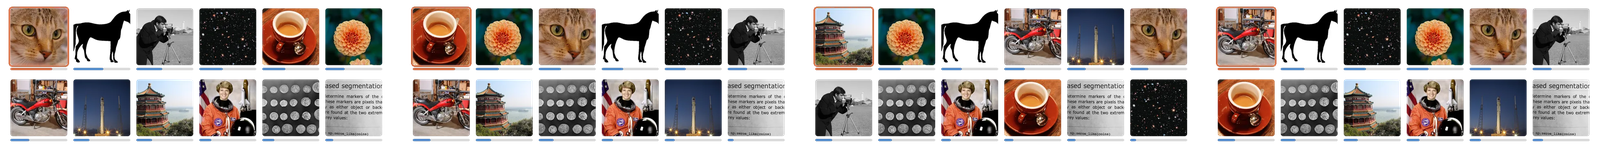

**Hỏi nhanh.** Trường cần chọn một trong hai checkpoint CLIP cho bộ tìm ảnh. So hai checkpoint bằng cách nào?

- A. So cosine trung bình của kết quả top-1 hai bên
- B. So loss pretraining mà hai nhà phát hành công bố
- C. Chọn checkpoint có softmax top-1 tự tin hơn
- D. Đánh dấu ảnh đúng cho một tập query, rồi so recall@k

<details><summary>Đáp án</summary>

D. Đánh dấu ảnh đúng cho một tập query, rồi so recall@k

Cosine và softmax của hai model khác nhau không cùng thang. Một model có thể cho cosine thường quanh 0.3, model khác quanh 0.6, mà không model nào tốt hơn vì thế. Loss pretraining đo trên dữ liệu, batch và temperature của nhà phát hành, không phải trên ảnh của trường. Chỉ phép đo trên đúng nhiệm vụ, với đáp án độc lập với model, mới so được hai checkpoint.

</details>

## Khi đi thi

- **Tận dụng ảnh không nhãn khi luật cho phép.** Với vài trăm nhãn và nhiều ảnh không nhãn, contrastive pretraining trên dữ liệu được phát rồi linear probe là một hướng. Luôn so với encoder chưa train và với baseline supervised cùng augmentation, bằng CV trên ảnh có nhãn.
- **Chọn augmentation theo bất biến của đề.** Đọc mô tả dữ liệu để biết vị trí, góc, màu nào thực sự biến thiên; chỉ dùng phép biến đổi không đổi nhãn.
- **Đọc loss contrastive theo mốc $\log K$.** Loss chỉ so được khi cùng batch và cùng $\tau$; chọn checkpoint bằng metric downstream.
- **Kiểm luật dùng model.** Đề cấm pretrained thì chỉ còn đường tự train encoder trên dữ liệu được phát; CLIP chỉ dùng khi đề cho phép và có asset offline.
- **Ước lượng bộ nhớ, cache embedding.** Ma trận similarity $2N\times2N$ tăng theo bình phương batch. Encoder cố định thì encode kho ảnh một lần, lưu kèm checkpoint và processor.
- **Đo retrieval bằng recall@k trên query giữ riêng.** Ghi prompt và thứ tự lớp; đổi câu mô tả cũng có thể đổi đáp án.

## Tóm tắt

Self-supervised learning tạo mục tiêu từ chính dữ liệu; mục tiêu chỉ tốt khi giả định của nó đúng với nhiệm vụ đích. Contrastive learning kéo cặp positive lại gần và đẩy negative ra xa bằng cross-entropy trên ma trận similarity; negative chặn lời giải sụp về vector hằng. Temperature quyết định lực đẩy dồn vào negative khó đến đâu, còn số ứng viên đặt mốc $\log K$ cho loss. Trên ảnh hình học, encoder học không nhãn nâng probe F1 từ 0.764 (cùng kiến trúc chưa train) lên 0.968. CLIP áp cùng cơ chế cho ảnh–chữ để tìm kiếm và zero-shot; chất lượng được đo bằng recall@k trên query của chính bài toán.

## Kiểm tra cuối bài

**Câu 1.** Contrastive loss của CLIP kéo cặp đúng lại gần và tách cặp sai ra xa. Cộng cùng một hằng số $c$ vào mọi ô trong hàng $i$ của ma trận điểm $S$, trước khi chia cho $\tau$. Loss ảnh sang chữ của hàng $i$ thay đổi thế nào?

- A. Giảm, vì logit cặp đúng tăng thêm $c$
- B. Tăng, vì logit mọi cặp sai đều tăng thêm $c$
- C. Không đổi, nhưng chỉ khi $c$ nhỏ hơn $\tau$
- D. Không đổi, với mọi giá trị của $c$

<details><summary>Đáp án</summary>

D. Không đổi, với mọi giá trị của $c$

Tử và mẫu của softmax cùng nhân thêm $e^{c/\tau}$, nên thừa số này triệt tiêu với mọi $c$. Loss chỉ đo cặp đúng hơn các cặp sai bao nhiêu. Nâng đồng loạt mọi điểm của một ảnh thì không được thưởng gì. Hai phương án “giảm” và “tăng” chỉ nhìn một nửa phân số.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 259](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=93)

</details>

**Câu 2.** Một hàng InfoNCE có cosine với positive là 0.5, với hai negative đều là 0, và $\tau = 0.5$. Loss của hàng này xấp xỉ bao nhiêu?

- A. 0.313
- B. 0.551
- C. 0.794
- D. 1.099

<details><summary>Đáp án</summary>

B. 0.551

Logits là 1, 0, 0, nên loss bằng $-\log\frac{e}{e + 2} = \log(1 + 2e^{-1}) \approx 0.551$. 0.794 là quên chia cho $\tau$. 0.313 là chỉ tính một negative. 1.099 bằng $\log 3$, là mốc đoán mò khi ba logit bằng nhau.

</details>

**Câu 3.** Kho 20 000 ảnh đã được encode và chuẩn hóa thành `I` shape `(20000, 512)`. Query chữ đã chuẩn hóa là `q` shape `(512,)`. Dòng nào trả về chỉ số của 10 ảnh phù hợp nhất?

- A. `np.argsort(I @ q)[:10]`
- B. `np.argsort(-(I.T @ q))[:10]`
- C. `np.argsort(-(q @ I))[:10]`
- D. `np.argsort(-(I @ q))[:10]`

<details><summary>Đáp án</summary>

D. `np.argsort(-(I @ q))[:10]`

`I @ q` cho 20 000 cosine. `argsort` xếp tăng dần, nên phải đổi dấu để điểm cao nhất lên đầu. Bỏ dấu trừ là lấy 10 ảnh kém nhất. `I.T @ q` nhân `(512, 20000)` với `(512,)`, còn `q @ I` nhân `(512,)` với `(20000, 512)`, nên cả hai đều lỗi shape.

</details>

**Câu 4.** Có bốn nguồn tín hiệu để train một encoder ảnh. (1) Đoán vùng ảnh bị che ngẫu nhiên. (2) Kéo gần hai view augmentation của cùng một ảnh. (3) Nhãn lớp do người gán cho từng ảnh. (4) Caption đi kèm ảnh trên web. Target của nguồn nào chứa thông tin do con người viết hoặc gán cho từng ảnh?

- A. Chỉ (3)
- B. (3) và (4)
- C. (1), (3) và (4)
- D. Không nguồn nào, vì đều thu thập tự động được

<details><summary>Đáp án</summary>

B. (3) và (4)

Ở (1) và (2), target được tạo bằng code từ chính ảnh: vùng che chọn ngẫu nhiên, view tạo bằng augmentation. Nhãn ở (3) do người gán. Caption ở (4) do người viết, dù không viết cho nhiệm vụ của ta. Vì vậy CLIP học từ một dạng giám sát yếu bằng ngôn ngữ, chứ không phải không có thông tin nhãn. Thu thập tự động không có nghĩa là thông tin không do người tạo ra.

</details>

**Câu 5.** CLIP học embedding ảnh và chữ được căn chỉnh với nhau. Một kho gồm 5000 ảnh và 5000 đoạn mô tả được encode bằng cùng checkpoint, chuẩn hóa rồi để chung một index. Tìm ảnh bằng câu chữ, chỉ trên phần ảnh, đạt recall@5 cao. Nhưng khi query là một ảnh, top-10 toàn là ảnh, dù có đoạn mô tả rất khớp với ảnh ấy. Vì sao?

- A. Text encoder lỗi nên vector chữ gần như ngẫu nhiên
- B. Thiếu bước softmax có temperature trước khi xếp hạng
- C. Loss không đặt cosine ảnh–ảnh và ảnh–chữ về cùng một thang
- D. Ảnh mang nhiều thông tin hơn chữ nên gần nhau hơn

<details><summary>Đáp án</summary>

C. Loss không đặt cosine ảnh–ảnh và ảnh–chữ về cùng một thang

Contrastive loss của CLIP chỉ so một ảnh với các caption trong batch, và ngược lại. Cộng cùng một hằng số vào mọi điểm của một hàng không đổi loss, nên loss không quy định cosine ảnh–chữ phải lớn cỡ nào so với cosine ảnh–ảnh. Thực tế embedding ảnh và embedding chữ của CLIP nằm ở hai vùng tách nhau, gọi là modality gap. Một cặp ảnh–chữ khớp thường có cosine thấp hơn hai ảnh cùng loại. Vì vậy chỉ nên xếp hạng trong cùng một loại ứng viên: tìm chữ cho ảnh trên index chữ, tìm ảnh cho ảnh trên index ảnh. Text encoder lỗi thì tìm ảnh bằng câu chữ cũng hỏng, trái với recall@5 cao. Softmax đơn điệu nên không đổi thứ hạng. Mọi vector đã chuẩn hóa về độ dài 1, và “nhiều thông tin hơn” không làm cosine ảnh–ảnh cao hơn.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 258](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=92)

</details>

**Câu 6.** Contrastive kiểu SimCLR cần batch 512 ảnh, nhưng GPU chỉ chứa được 128. Đội dùng gradient accumulation: chạy 4 micro-batch 128 ảnh, cộng gradient lại rồi mới gọi `optimizer.step()`. So với batch 512 thật, điều nào đúng?

- A. Mỗi view chỉ có 254 negative thay vì 1022
- B. Hai cách tương đương, vì gradient được cộng đủ 512 ảnh
- C. Hai cách tương đương nếu chia loss cho 4 trước `backward`
- D. Vẫn đủ 1022 negative, chỉ gradient nhỏ hơn

<details><summary>Đáp án</summary>

A. Mỗi view chỉ có 254 negative thay vì 1022

Loss của một view phụ thuộc các view khác trong cùng lần forward. Mẫu số chỉ chứa view của micro-batch, nên có $2\cdot 128 - 2 = 254$ negative thay vì $2\cdot 512 - 2 = 1022$, và mốc đoán mò cũng đổi từ $\log 1023$ thành $\log 255$. Accumulation chỉ tương đương batch lớn khi loss là tổng độc lập theo từng mẫu (bài 3.7), mà contrastive loss thì không như vậy. Chia loss cho 4 chỉ sửa độ lớn gradient. Muốn có nhiều negative hơn bộ nhớ cho phép, người ta thường giữ một hàng đợi embedding từ các batch trước, như MoCo.

</details>

**Câu 7.** SimCLR với batch $N = 4096$ ảnh. Riêng ma trận logits `float32` của loss chiếm bao nhiêu bộ nhớ, biết 1 MiB bằng $2^{20}$ byte?

- A. 64 MiB
- B. 128 MiB
- C. 256 MiB
- D. 1024 MiB

<details><summary>Đáp án</summary>

C. 256 MiB

Có $2N = 8192$ view, nên ma trận có $8192\times 8192 \approx 6.7\cdot 10^7$ số, mỗi số 4 byte, tổng cộng $2^{28}$ byte, tức 256 MiB. Đếm $N\times N$ thì ra 64 MiB. Nhân 4 hai lần thì ra 1024 MiB. Softmax và gradient còn cần thêm vài bản cùng cỡ, nên batch lớn tốn bộ nhớ theo bình phương.

</details>

**Câu 8.** Biểu diễn pretrained của CLIP dùng được cho nhiều nhiệm vụ. Câu lạc bộ có 300 ảnh dụng cụ thí nghiệm đã gán 5 nhãn. Zero-shot bằng tên lớp đạt macro-F1 0.62 trên validation. Đề cho phép dùng CLIP. Bước tiếp theo nên là gì?

- A. Linear probe trên embedding ảnh đã cache
- B. Fine-tune toàn bộ CLIP với learning rate lớn
- C. Đổi prompt đến khi validation vượt 0.9
- D. Train CNN từ đầu trên 300 ảnh, bỏ CLIP

<details><summary>Đáp án</summary>

A. Linear probe trên embedding ảnh đã cache

Đã có nhãn thì nên dùng chúng. Cache embedding ảnh một lần, rồi train linear probe trên embedding đóng băng. Cách này rẻ, ít tham số, và so được trực tiếp với zero-shot trên cùng validation. Fine-tune toàn bộ với 300 ảnh và learning rate lớn dễ phá biểu diễn có sẵn (bài 4.3). Đổi prompt đến khi validation đẹp rồi báo chính điểm ấy thì điểm sẽ lạc quan quá mức. CNN từ đầu với 300 ảnh bỏ phí biểu diễn đã học.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 262](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=94)

</details>

**Câu 9.** Trên 200 query của trường, checkpoint A có recall@1 bằng 0.42 và recall@10 bằng 0.81. Checkpoint B có recall@1 bằng 0.48 và recall@10 bằng 0.74. Giao diện hiện 10 ảnh đầu trên một trang để người dùng tự chọn. Nên chọn checkpoint nào?

- A. A, vì cách dùng này ứng với recall@10
- B. B, vì recall@1 là metric chuẩn của retrieval
- C. B, vì ảnh đúng của B thường lên đầu hơn
- D. Không chọn được, vì hai recall mâu thuẫn nhau

<details><summary>Đáp án</summary>

A. A, vì cách dùng này ứng với recall@10

Người dùng thấy cả 10 ảnh, nên điều quan trọng là ảnh đúng có nằm trong trang đầu không. A làm được với 81% số query, B với 74%. Recall@1 quan trọng khi hệ thống chỉ trả về một kết quả. Hai metric không mâu thuẫn, chúng đo hai cách dùng khác nhau. Chênh 7 điểm trên 200 query là 14 query, nên vẫn cần kiểm xem nó có vượt mức dao động giữa các tập query không.

</details>

**Câu 10.** Kho ảnh của trường có nhiều ảnh chụp liên tiếp gần giống nhau. Đội fine-tune contrastive ảnh–caption trên 80% số ảnh, chọn ngẫu nhiên từng ảnh, rồi đánh giá retrieval trên 20% còn lại, và được recall@5 rất cao. Cách đánh giá này có vấn đề gì?

- A. Batch quá nhỏ nên recall bị phóng đại
- B. Các ảnh gần trùng rơi vào cả hai phần
- C. 20% quá ít, cần đánh giá trên 50% số ảnh
- D. Recall@5 luôn cao, nên phải dùng recall@1

<details><summary>Đáp án</summary>

B. Các ảnh gần trùng rơi vào cả hai phần

Chia ngẫu nhiên từng ảnh đưa các ảnh chụp liên tiếp vào cả phần train lẫn phần đánh giá, nên model chỉ cần nhớ lại gần đúng ảnh đã thấy. Chia theo nhóm, như theo buổi chụp hay sự kiện ở Chương 1, mới đo được khả năng tìm ảnh mới. Batch không làm recall trên tập đánh giá bị phóng đại. Tăng phần đánh giá không sửa được rò rỉ. Recall@5 cũng không tự động cao.

</details>

## Đọc thêm

- Chen và cộng sự — [SimCLR](https://arxiv.org/abs/2002.05709): đọc vai trò view, projection và contrastive objective.
- Oord và cộng sự — [Representation Learning with Contrastive Predictive Coding](https://arxiv.org/abs/1807.03748): nguồn của InfoNCE, đọc vì sao loss này gắn với việc phân biệt mẫu thật giữa nhiều mẫu nhiễu.
- He và cộng sự — [MoCo](https://arxiv.org/abs/1911.05722): hàng đợi embedding cho nhiều negative hơn mức batch cho phép.
- Radford và cộng sự — [CLIP](https://arxiv.org/abs/2103.00020): xem cách ghép encoder ảnh–chữ, temperature học được và dùng mô tả cho zero-shot.
- [Transformers — CLIP](https://huggingface.co/docs/transformers/model_doc/clip): đối chiếu processor, normalize và đầu ra khi có checkpoint cục bộ.

Nguồn ảnh: ảnh tháp và ảnh hoa là ảnh mẫu `china.jpg` (danielbuechele, Flickr, CC BY 2.0) và `flower.jpg` (vultilion, Flickr, CC BY 2.0) kèm scikit-learn; trong hình CLIP còn có `chelsea`, `coffee`, `astronaut`, `rocket`, `horse`, `coins`, `camera`, `hubble_deep_field`, `page`, `stereo_motorcycle` kèm scikit-image (public domain hoặc CC0).